# Hotel booking cancellation: model training, comparison & selection

**VoidMain Technologies AI internship · Task 3: Machine Learning Application & Model Evaluation**

This notebook walks through the whole modelling workflow, top to bottom. It calls the same
functions as `python main.py` (everything lives in `src/`). Cheap steps run live here. The
expensive ones (tuning, learning curves, temporal check) are loaded from the results that
`main.py` saved, so the notebook runs in about a minute and always shows the same numbers as
the README and the web app.

| Brief requirement | Section |
|---|---|
| Practical classification problem | 1 |
| Appropriate validation | 3 |
| Multiple algorithms + baseline | 4 |
| Relevant metrics | 4, 5 |
| Hyperparameter tuning | 6 |
| Over/underfitting | 7 |
| Justified model selection | 8 |
| Threshold, final test evaluation, explainability | 9, 10, 11 |

In [1]:
import json
import sys
from pathlib import Path

import joblib
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import config
from src.evaluate import compute_metrics, report_dict
from src.models import build_model_zoo
from src.train import cross_validate_model, prepare_dataset

config.setup_logging()
pd.set_option("display.width", 160, "display.max_columns", 30, "display.precision", 4)
FIG = config.FIGURES_DIR
summary = json.loads(config.APP_DASHBOARD_CACHE.read_text(encoding="utf-8"))
metric, label = config.PRIMARY_METRIC, config.METRIC_LABELS[config.PRIMARY_METRIC]

## 1. Problem

Predict `is_canceled` (1 = canceled) for a hotel booking at the time it is made. A hotel that
knows which bookings will cancel can overbook just enough to keep rooms full: missed
cancellations leave rooms empty, false alarms mean relocating overbooked guests.

Data: *Hotel booking demand* (Antonio, Almeida & Nunes, 2019), real bookings from a city
hotel and a resort hotel in Portugal, arrivals July 2015 to August 2017.

## 2. Data: reused from Task 2

Cleaning and feature engineering are **copied unchanged from Task 2**
([hotel-booking-preprocessing](https://github.com/Krishna141414/hotel-booking-preprocessing)):
drop exact duplicates, zero-guest rows, negative ADR and impossible counts, cap extreme ADR,
fill structural missing values, and add 10 row-wise features. This project only adds what
modelling needs: the leakage columns are dropped right away and the split is fixed.

In [2]:
dataset = prepare_dataset()
print(f"Raw: {dataset.raw_shape[0]:,} rows x {dataset.raw_shape[1]} columns")
print(f"Clean + engineered: {len(dataset.featured):,} rows")
print(f"Train / test: {len(dataset.train_rows):,} / {len(dataset.test_rows):,}")
print(f"Cancel rate train / test: {dataset.y_train.mean():.3%} / {dataset.y_test.mean():.3%}")
print(
    f"Model inputs: {len(dataset.groups.all)} (country / is_domestic dropped) "
    f"({len(dataset.groups.numeric)} numeric, {len(dataset.groups.binary)} binary, "
    f"{len(dataset.groups.categorical)} categorical)"
)

22:51:16 | INFO    | src.data       | Loaded 119,390 rows x 32 columns from hotel_bookings.csv


22:51:16 | INFO    | src.data       | -> Drop zero-guest bookings


22:51:16 | INFO    | src.data       | Zero-guest bookings dropped: 180


22:51:16 | INFO    | src.data       | -> Drop negative ADR


22:51:16 | INFO    | src.data       | Negative-ADR rows dropped: 1


...

22:51:18 | INFO    | src.data       | Cleaning done: 119,390 -> 87,208 rows (32,182 removed, 27.0%)


22:51:18 | INFO    | src.features   | Engineered 10 features: ['total_nights', 'total_guests', 'has_children', 'adr_per_person', 'stay_value', 'arrival_month_num', 'arrival_weekday', 'arrival_season', 'is_domestic', 'previous_cancel_ratio']


22:51:18 | INFO    | src.features   | Shape after feature engineering: 87,208 rows x 41 columns


22:51:18 | INFO    | src.train      | Split: 69,766 train / 17,442 test rows (stratified, cancel rate 27.5% / 27.5%); 31 inputs


Raw: 119,390 rows x 32 columns
Clean + engineered: 87,208 rows
Train / test: 69,766 / 17,442
Cancel rate train / test: 27.511% / 27.514%
Model inputs: 31 (country / is_domestic dropped) (18 numeric, 4 binary, 9 categorical)


### Leakage review

* `reservation_status` / `reservation_status_date` reveal the outcome, so they are dropped right after cleaning.
* `assigned_room_type` is set at check-in (canceled bookings never get there) and is **dropped**.
* `booking_changes` is counted up to the outcome date, so early cancellations have had less time to change. It's **dropped**, the safer option.
* `days_in_waiting_list` is known once the booking is confirmed and is **kept**.
* `country` / `is_domestic` are **dropped as a precaution**. Nationality may only be recorded
  at check-in (which canceled bookings never reach), so it may encode the outcome. The
  with-country result is kept only as an ablation, shown below.

The ablation below (from `main.py`) is the evidence: adding the two post-booking columns
lifts the CV score, which is the classic sign that they carry outcome information.

In [3]:
pd.DataFrame(summary["ablation"]).set_index("variant")

,inputs,pr_auc,pr_auc_std,roc_auc,delta
variant,,,,,
Selected features (final),31,0.7149,0.0050,0.8517,0.0000
+ booking_changes,32,0.7219,0.0049,0.8557,0.0070
+ assigned_room_type,32,0.7307,0.0047,0.8621,0.0158
+ both post-booking columns,33,0.7374,0.0052,0.8658,0.0225
- days_in_waiting_list,30,0.7144,0.0049,0.8515,-0.0005
+ country & is_domestic,33,0.7785,0.0059,0.9038,0.0636


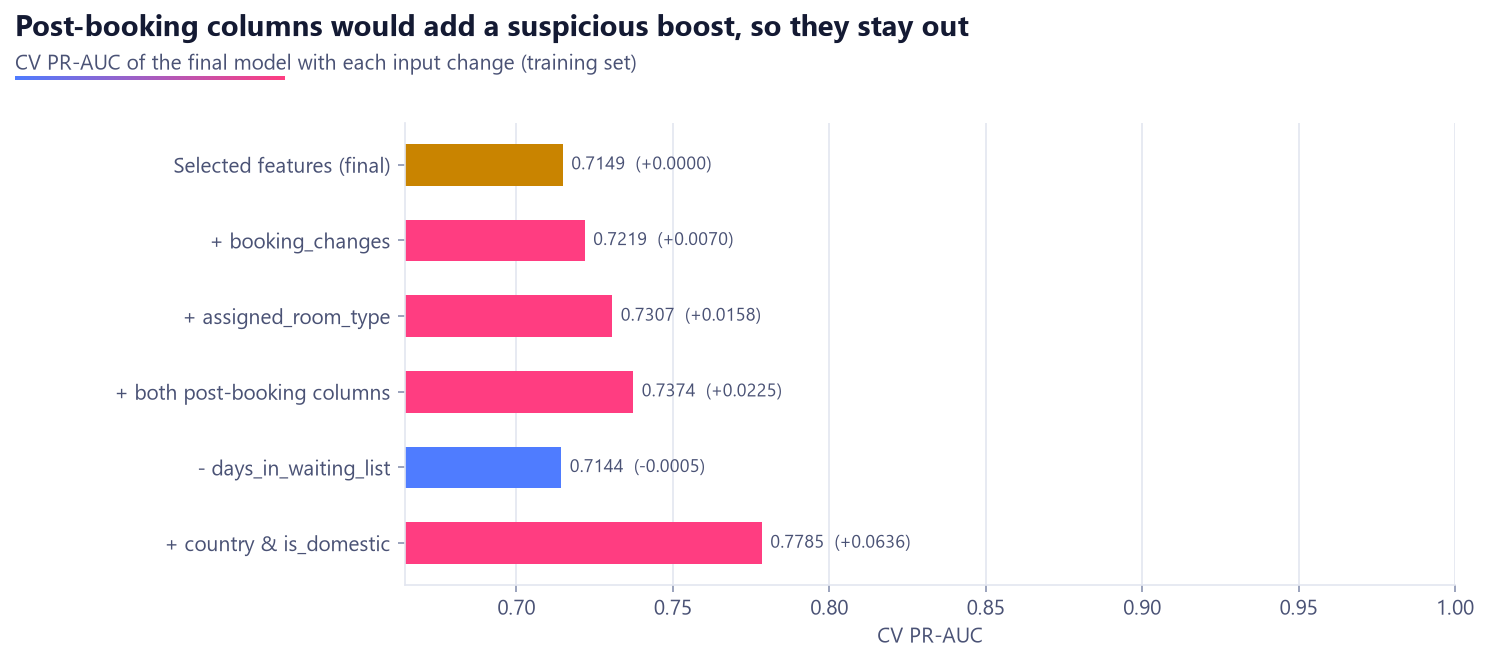

In [4]:
display(Image(FIG / "15_leakage_ablation.png", width=820))

### With vs without country

The same final-model settings trained with nationality added back. This is evaluation only:
the drop was decided on the leakage argument, not on these numbers.

In [5]:
ca = summary["country_ablation"]
rows = {}
for variant in ("without", "with"):
    v = ca[variant]
    rows[f"{variant} country ({v['inputs']} inputs)"] = {
        "CV PR-AUC": v["cv"][metric]["mean"],
        "CV ROC-AUC": v["cv"]["roc_auc"]["mean"],
        "Test PR-AUC": v["test"][metric],
        "Test ROC-AUC": v["test"]["roc_auc"],
        f"Test F1 @ {ca['threshold']:.2f}": v["test"]["f1"],
    }
display(pd.DataFrame(rows))
ev = ca["evidence"]
print(
    f"Portuguese guests: {ev['domestic_share']:.0%} of bookings, {ev['domestic_share_of_cancellations']:.0%} of cancellations "
    f"({ev['domestic_cancel_rate']:.0%} vs {ev['foreign_cancel_rate']:.0%} cancel rate)"
)

,without country (31 inputs),with country (33 inputs)
CV PR-AUC,0.7149,0.7785
CV ROC-AUC,0.8517,0.9038
Test PR-AUC,0.7210,0.7831
Test ROC-AUC,0.8553,0.9064
Test F1 @ 0.54,0.6557,0.7187


Portuguese guests: 31% of bookings, 41% of cancellations (36% vs 24% cancel rate)


## 3. Validation setup

* **Stratified 80/20 train/test split** (seed 42, same split as Task 2). The test set is used
  **once**, after the final model and threshold are frozen.
* **Stratified 5-fold cross-validation** on the training set for every comparison, tuning and
  selection decision. All models use the same folds.
* **Pipelines everywhere**: scaling, the log1p choice and one-hot categories are fitted inside
  each training fold, so validation folds never leak into preprocessing.
* **Imbalance (27.5% canceled)**: stratified splits, `class_weight="balanced"` where the
  algorithm supports it, and PR-AUC as the primary metric rather than accuracy.
* **Extra realism check**: a temporal split (train on earlier arrivals, test on the latest
  20%) in section 12.

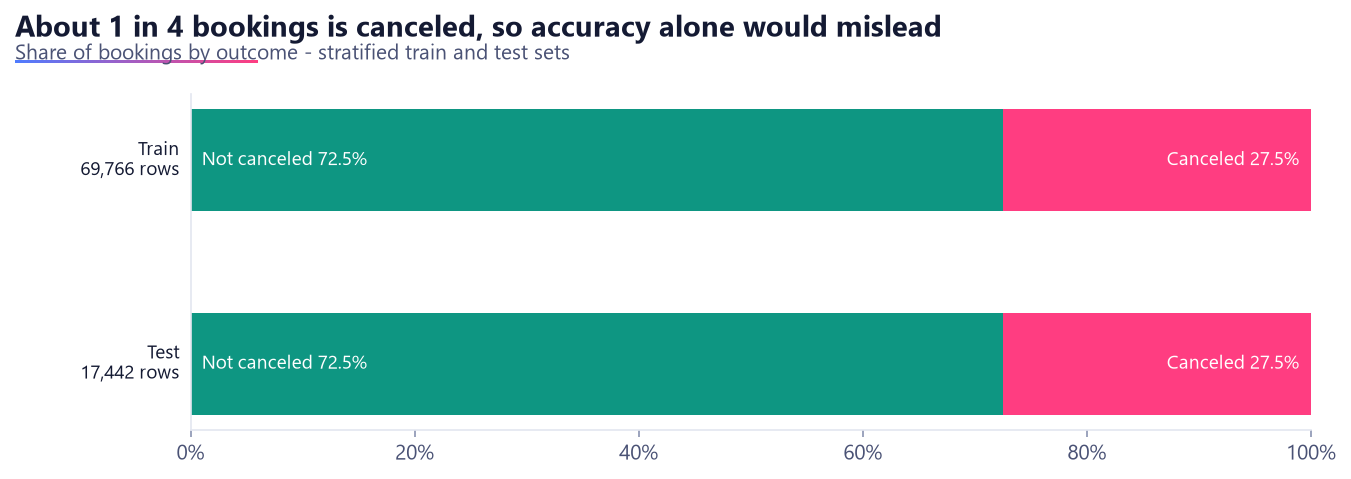

In [6]:
display(Image(FIG / "01_class_balance.png", width=760))

## 4. Baseline + five algorithms (5-fold CV)

As a live demonstration, the baseline and Logistic Regression are cross-validated here. The
numbers match the saved run because the folds are seeded.

In [7]:
zoo = build_model_zoo(dataset.groups)
live = {
    k: cross_validate_model(k, zoo[k], dataset.x_train, dataset.y_train)
    for k in ["dummy", "logreg"]
}
pd.DataFrame(
    {
        r.name: {m: f"{r.cv[m]['mean']:.4f} ± {r.cv[m]['std']:.4f}" for m in config.METRICS}
        for r in live.values()
    }
).rename(index=config.METRIC_LABELS)

22:51:18 | INFO    | src.models     | Model zoo: Dummy (most frequent), Logistic Regression, Decision Tree, Random Forest, HistGradientBoosting, K-Nearest Neighbors


22:51:21 | INFO    | src.train      |   Dummy (most frequent)          CV PR-AUC 0.2751 +/- 0.0000 | train 0.2751 | fold fit 0.5s


22:51:25 | INFO    | src.train      |   Logistic Regression            CV PR-AUC 0.6728 +/- 0.0077 | train 0.6735 | fold fit 1.2s


,Dummy (most frequent),Logistic Regression
Accuracy,0.7249 ± 0.0000,0.7306 ± 0.0057
Precision,0.0000 ± 0.0000,0.5071 ± 0.0071
Recall,0.0000 ± 0.0000,0.7496 ± 0.0091
F1,0.0000 ± 0.0000,0.6049 ± 0.0080
ROC-AUC,0.5000 ± 0.0000,0.8184 ± 0.0069
PR-AUC,0.2751 ± 0.0000,0.6728 ± 0.0077


All models (from `reports/model_comparison.csv`):

In [8]:
comparison = pd.read_csv(config.MODEL_COMPARISON_PATH)
cols = (
    ["model", "rank"]
    + [f"cv_{m}_mean" for m in config.METRICS]
    + [f"test_{m}" for m in config.METRICS]
)
comparison[cols].sort_values("rank", na_position="last")

,model,rank,cv_accuracy_mean,cv_precision_mean,cv_recall_mean,cv_f1_mean,cv_roc_auc_mean,cv_average_precision_mean,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,test_average_precision
4,Random Forest (tuned),1.0,0.7862,0.5900,0.7309,0.6529,0.8529,0.7157,0.7919,0.5989,0.7381,0.6613,0.8576,0.7232
6,HistGradientBoosting (tuned),2.0,0.7779,0.5746,0.7417,0.6476,0.8517,0.7149,0.7836,0.5836,0.7445,0.6543,0.8553,0.7210
5,HistGradientBoosting,3.0,0.7782,0.5751,0.7422,0.6480,0.8516,0.7147,0.7789,0.5766,0.7395,0.6480,0.8539,0.7220
3,Random Forest,4.0,0.8015,0.6350,0.6551,0.6449,0.8465,0.6956,0.8052,0.6410,0.6637,0.6521,0.8511,0.7040
1,Logistic Regression,5.0,0.7306,0.5071,0.7496,0.6049,0.8184,0.6728,0.7327,0.5097,0.7437,0.6049,0.8165,0.6715
7,K-Nearest Neighbors,6.0,0.7832,0.6520,0.4551,0.5359,0.7969,0.6132,0.7872,0.6666,0.4536,0.5399,0.7948,0.6214
2,Decision Tree,7.0,0.7453,0.5373,0.5357,0.5365,0.6821,0.4214,0.7507,0.5476,0.5395,0.5435,0.6870,0.4294
0,Dummy (most frequent),NaN,0.7249,0.0000,0.0000,0.0000,0.5000,0.2751,0.7249,0.0000,0.0000,0.0000,0.5000,0.2751


In [9]:
comparison[
    [
        "model",
        "cv_fold_fit_time_s",
        "full_fit_time_s",
        "predict_ms_per_1k",
        "size_mb",
        "training_rows",
    ]
]

,model,cv_fold_fit_time_s,full_fit_time_s,predict_ms_per_1k,size_mb,training_rows
0,Dummy (most frequent),0.548,0.405,2.09,0.005,69766
1,Logistic Regression,1.350,0.871,3.05,0.007,69766
2,Decision Tree,1.365,1.002,2.60,0.460,69766
3,Random Forest,19.352,13.702,35.93,80.590,69766
4,Random Forest (tuned),37.017,12.644,20.79,16.636,69766
5,HistGradientBoosting,8.637,3.520,5.94,0.442,69766
6,HistGradientBoosting (tuned),38.780,5.714,6.54,0.890,69766
7,K-Nearest Neighbors,0.222,0.148,56.40,1.281,20000


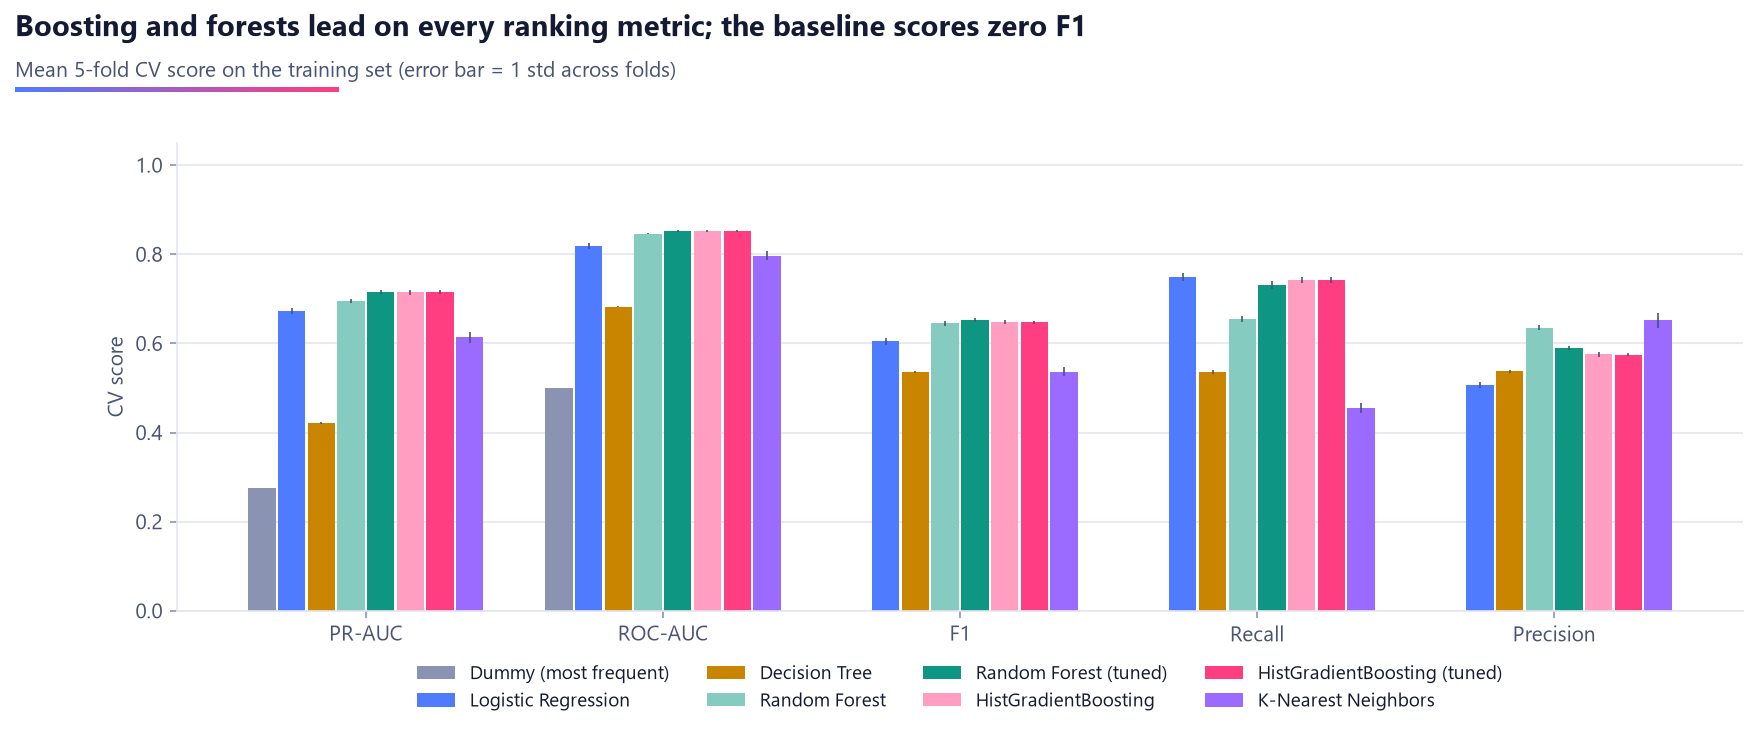

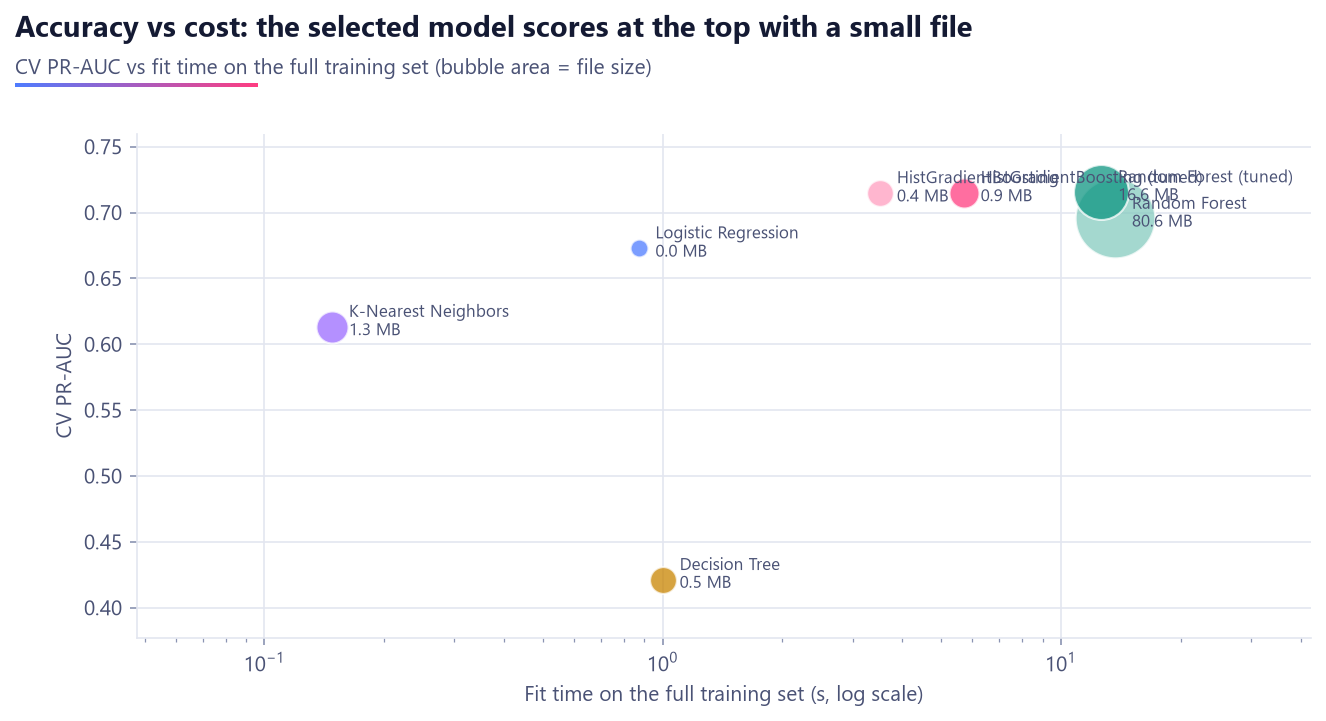

In [10]:
display(Image(FIG / "02_cv_model_comparison.png", width=900))
display(Image(FIG / "14_speed_vs_score.png", width=760))

## 5. ROC and precision-recall curves (test set)

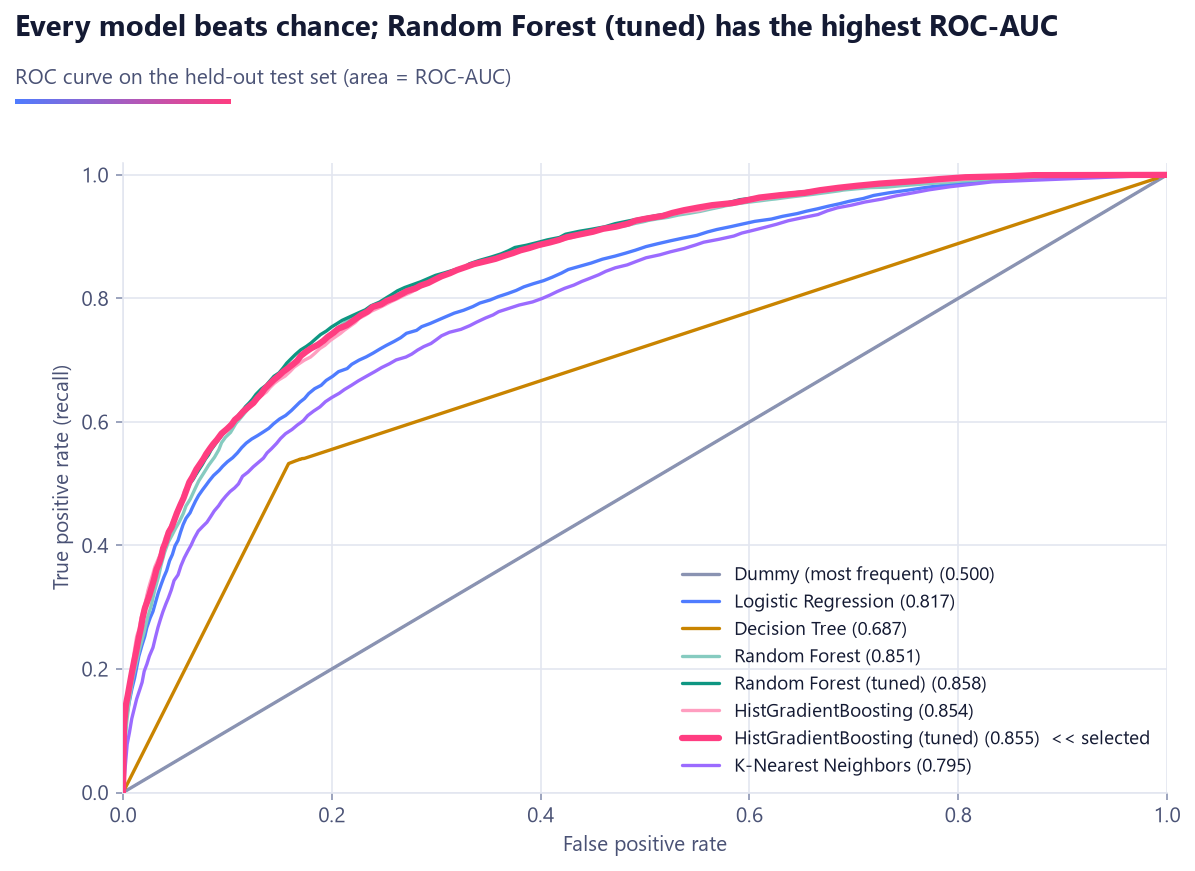

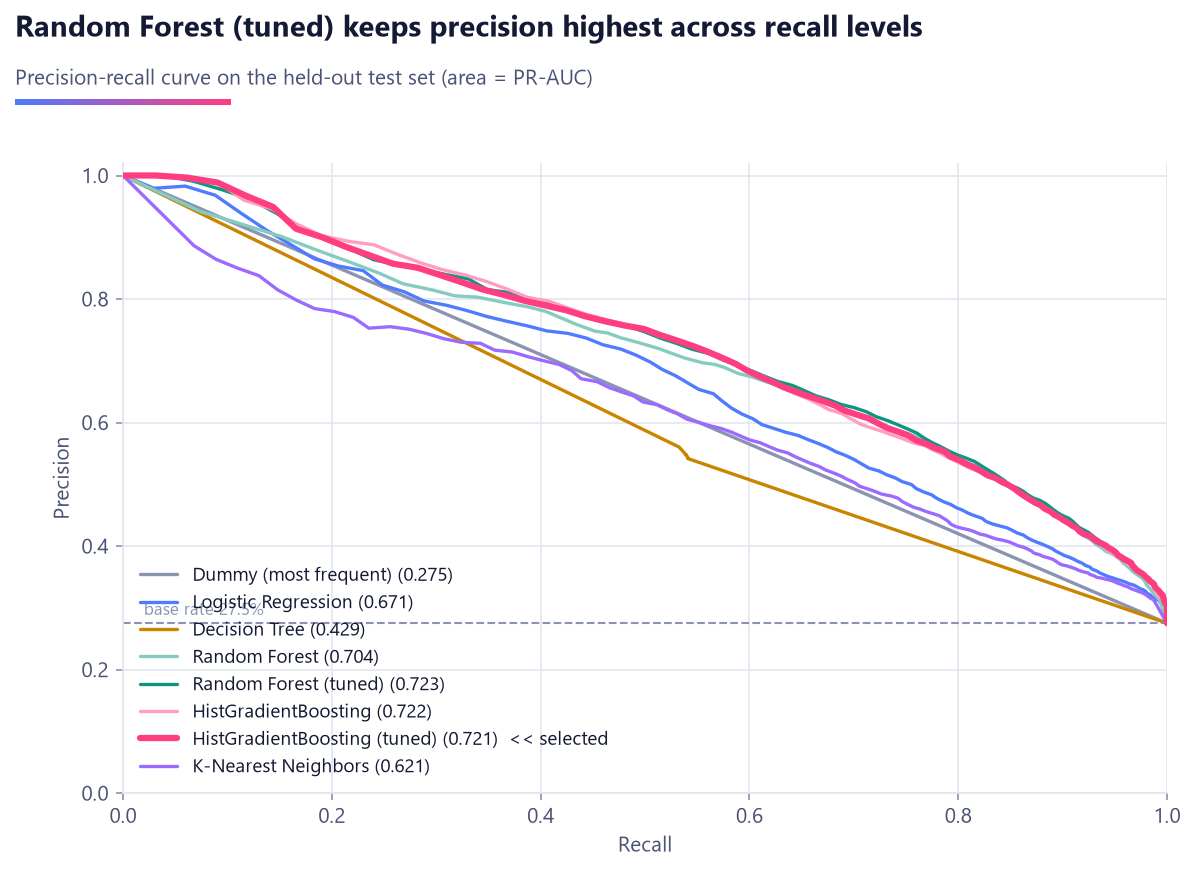

In [11]:
display(Image(FIG / "03_roc_curves.png", width=640))
display(Image(FIG / "04_pr_curves.png", width=640))

## 6. Hyperparameter tuning: RandomizedSearchCV on the top 2 models

Same 5 folds, every metric recorded for every sampled setting, best setting chosen on PR-AUC.

In [12]:
for m in summary["models"]:
    if m["search"]:
        s = m["search"]
        print(
            f"{m['name']}: {s['n_iter']} settings x {s['folds']} folds = {s['fits']} fits "
            f"in {s['search_time_s']:.0f}s"
        )
        print(f"  best params: {s['best_params']}")
        print(f"  CV {label}: {m['cv'][metric]['mean']:.4f} ± {m['cv'][metric]['std']:.4f}")
        base = next(x for x in summary["models"] if x["key"] == m["base"])
        print(
            f"  untuned:     {base['cv'][metric]['mean']:.4f}  ->  gain {m['cv'][metric]['mean'] - base['cv'][metric]['mean']:+.4f}"
        )
        display(pd.DataFrame(s["candidates"]).head(5))

Random Forest (tuned): 12 settings x 5 folds = 60 fits in 169s
  best params: {'n_estimators': 150, 'min_samples_leaf': 8, 'max_features': 0.2, 'max_depth': 24}
  CV PR-AUC: 0.7157 ± 0.0045
  untuned:     0.6956  ->  gain +0.0201


,params,cv,train,chosen
0,"{'n_estimators': 350, 'min_samples_leaf': 2, '...",0.7183,0.9615,False
1,"{'n_estimators': 150, 'min_samples_leaf': 2, '...",0.7174,0.9905,False
2,"{'n_estimators': 350, 'min_samples_leaf': 4, '...",0.7169,0.8543,False
3,"{'n_estimators': 150, 'min_samples_leaf': 8, '...",0.7157,0.8456,True
4,"{'n_estimators': 150, 'min_samples_leaf': 4, '...",0.7153,0.8598,False


HistGradientBoosting (tuned): 20 settings x 5 folds = 100 fits in 193s
  best params: {'min_samples_leaf': 40, 'max_leaf_nodes': 63, 'max_iter': 300, 'learning_rate': 0.03, 'l2_regularization': 0.1}
  CV PR-AUC: 0.7149 ± 0.0050
  untuned:     0.7147  ->  gain +0.0002


,params,cv,train,chosen
0,"{'min_samples_leaf': 10, 'max_leaf_nodes': 127...",0.7203,0.8812,False
1,"{'min_samples_leaf': 20, 'max_leaf_nodes': 127...",0.7183,0.9258,False
2,"{'min_samples_leaf': 10, 'max_leaf_nodes': 63,...",0.7180,0.8712,False
3,"{'min_samples_leaf': 40, 'max_leaf_nodes': 127...",0.7179,0.9024,False
4,"{'min_samples_leaf': 40, 'max_leaf_nodes': 63,...",0.7166,0.7937,False


## 7. Overfitting and underfitting

Train scores are the mean over the CV training folds. Rules: a train-CV gap above 0.05 means
overfitting; a small gap but a CV score more than 0.05 below the best model means underfitting.

In [13]:
table = pd.DataFrame(
    [
        {
            "model": m["name"],
            "train": m["train"][metric],
            "cv": m["cv"][metric]["mean"],
            "test": m["test"][metric],
            "train-cv gap": m["gap"],
            "diagnosis": m["diagnosis"]["label"],
            "why": m["diagnosis"]["reason"],
        }
        for m in summary["models"]
    ]
)
table

,model,train,cv,test,train-cv gap,diagnosis,why
0,Dummy (most frequent),0.2751,0.2751,0.2751,0.0000,Baseline,No learning at all: always predicts the majori...
1,Logistic Regression,0.6735,0.6728,0.6715,0.0007,Good fit,Small train-CV gap (0.001) and close to the be...
2,Decision Tree,0.9997,0.4214,0.4294,0.5783,Strong overfitting,Train score is 0.578 above CV: it memorises tr...
3,Random Forest,0.9995,0.6956,0.7040,0.3039,Strong overfitting,Train score is 0.304 above CV: it memorises tr...
4,Random Forest (tuned),0.8456,0.7157,0.7232,0.1299,Strong overfitting,Train score is 0.130 above CV: it memorises tr...
5,HistGradientBoosting,0.7957,0.7147,0.7220,0.0810,Mild overfitting,Train score is 0.081 above CV: it memorises tr...
6,HistGradientBoosting (tuned),0.7695,0.7149,0.7210,0.0546,Mild overfitting,Train score is 0.055 above CV: it memorises tr...
7,K-Nearest Neighbors,1.0000,0.6132,0.6214,0.3868,Strong overfitting,Train score is 0.387 above CV: it memorises tr...


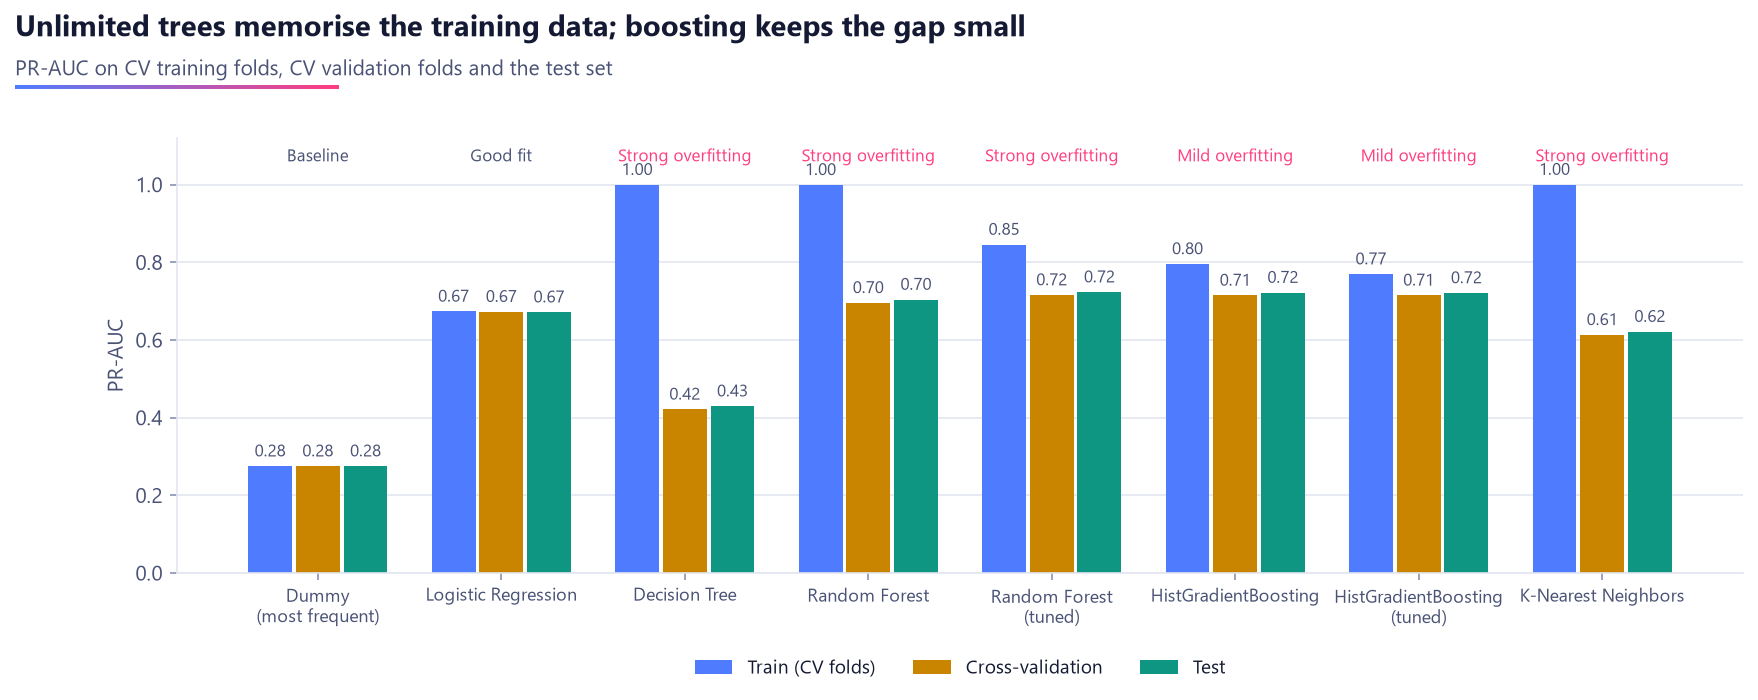

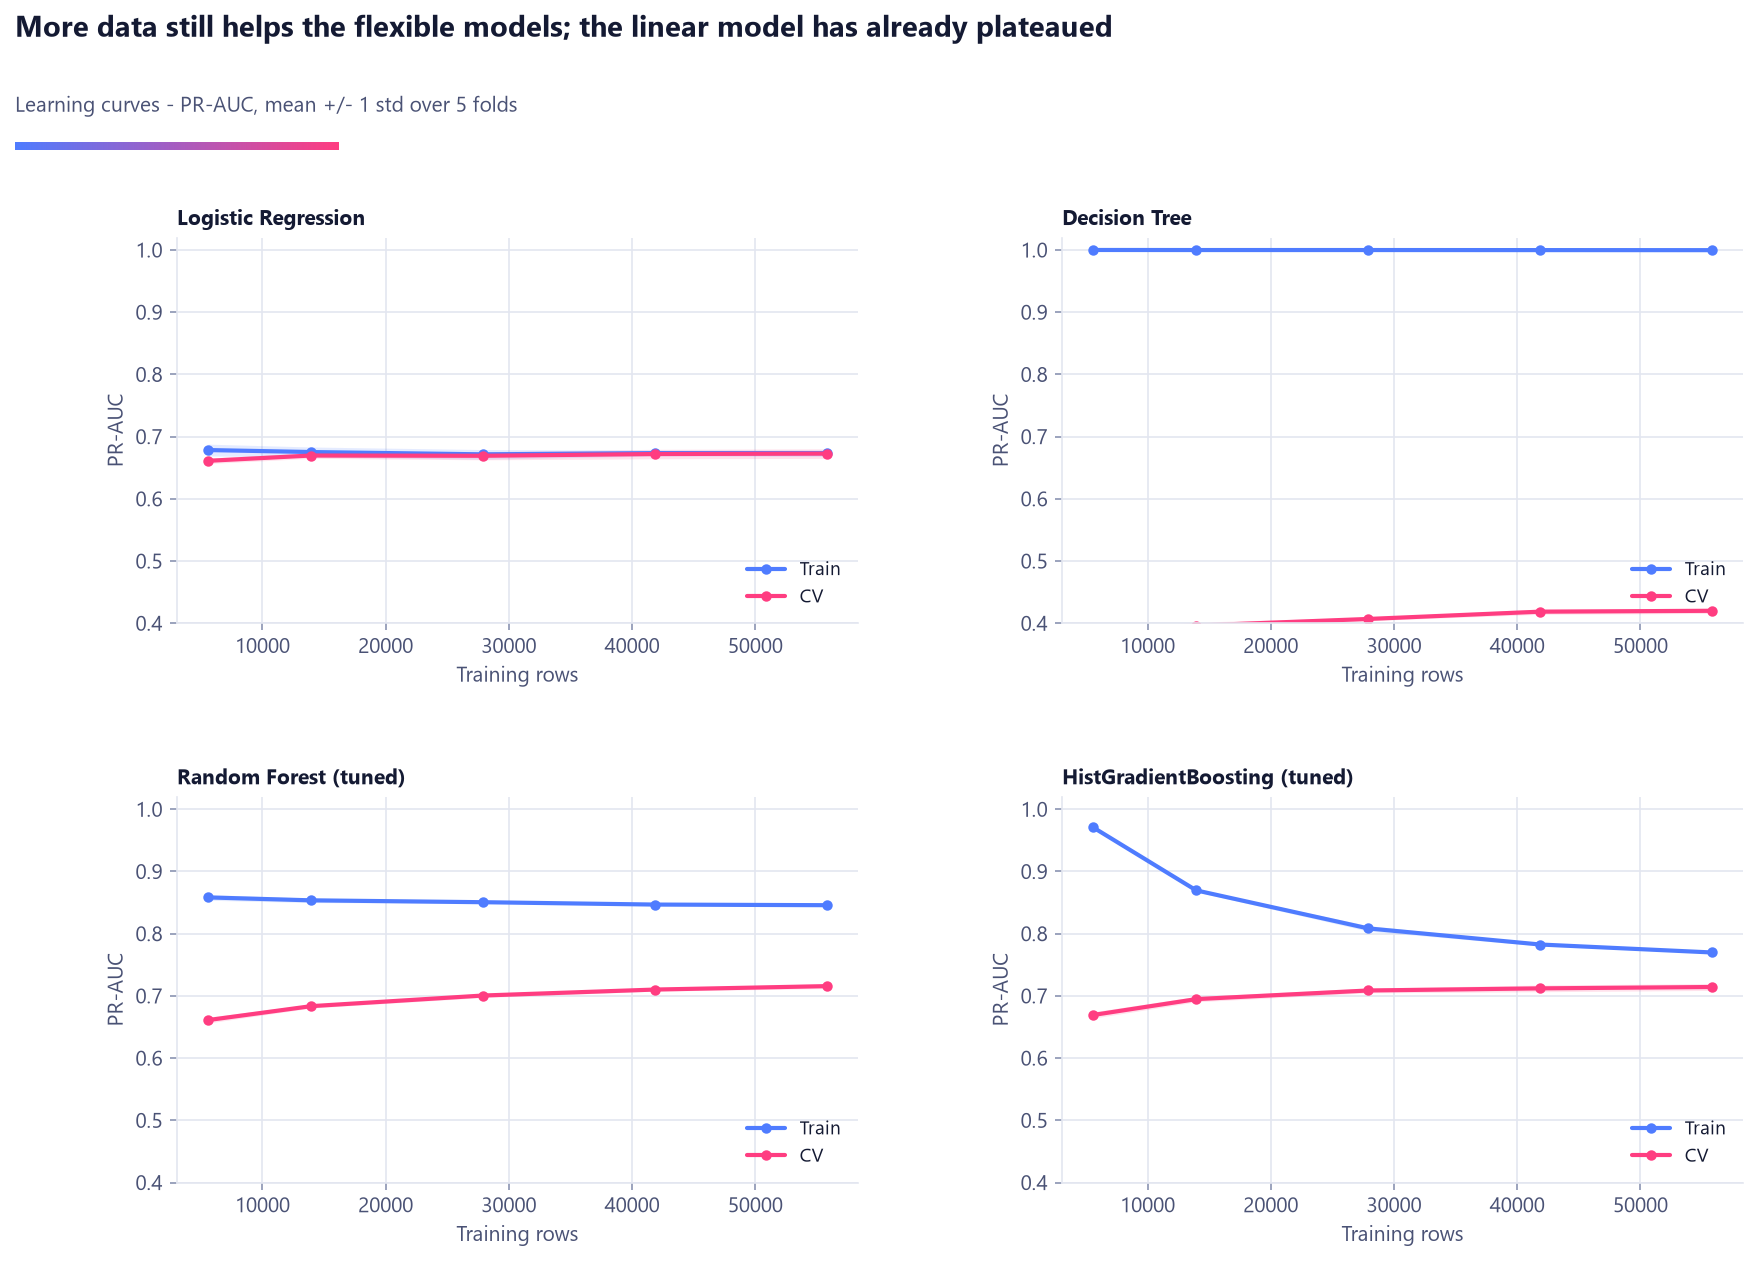

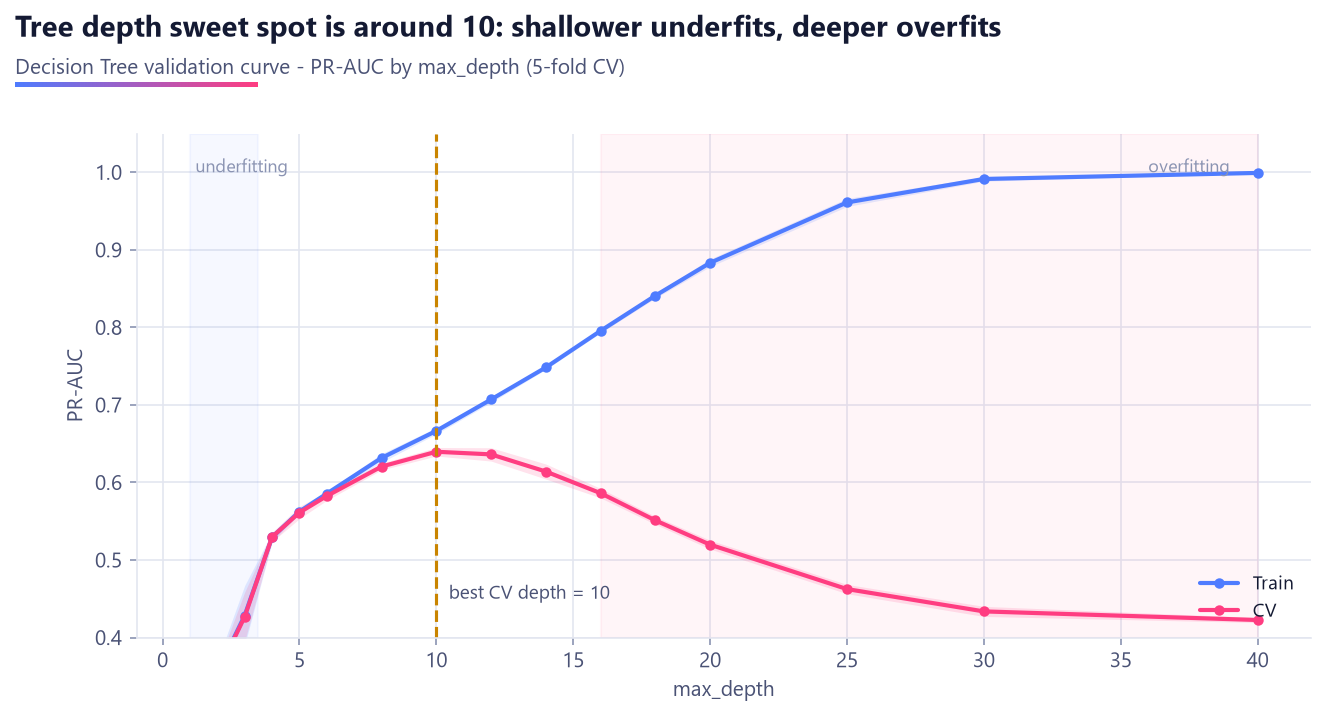

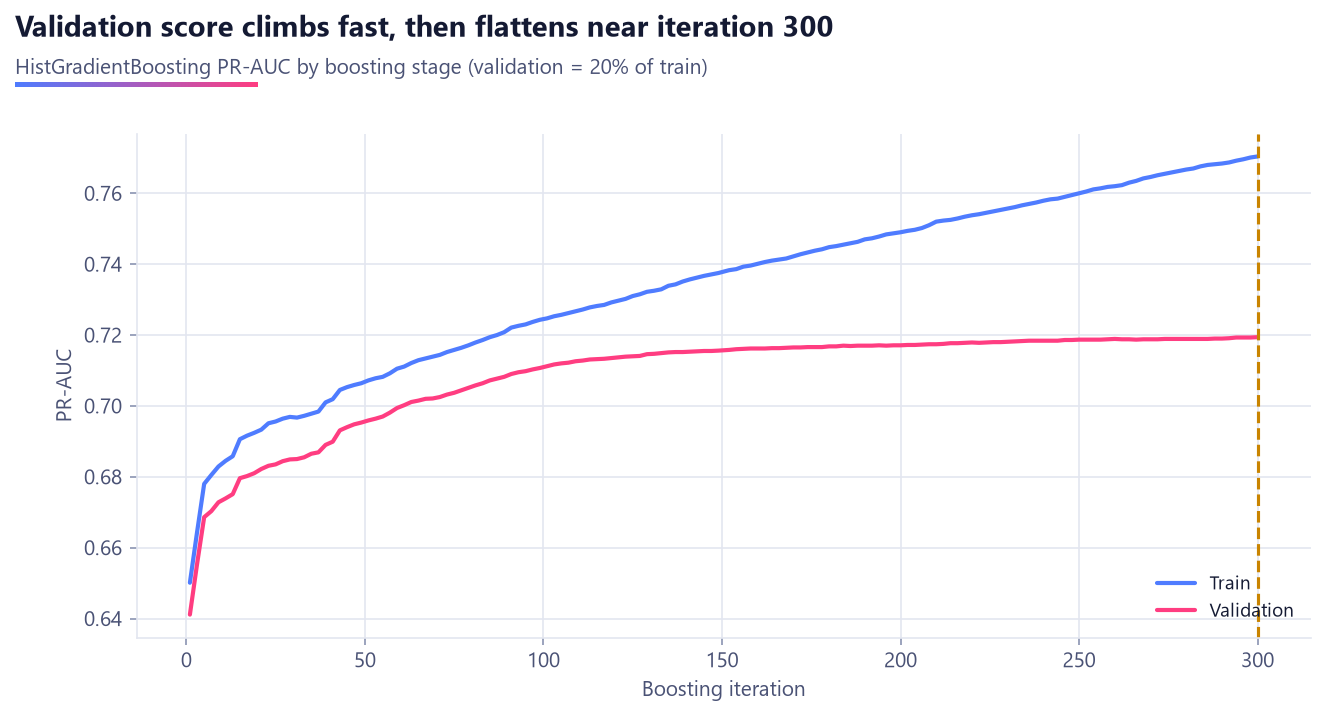

In [14]:
display(Image(FIG / "06_overfitting_gaps.png", width=900))
display(Image(FIG / "07_learning_curves.png", width=900))
display(Image(FIG / "08_validation_curve_depth.png", width=760))
display(Image(FIG / "16_boosting_replay.png", width=760))

## 8. Model selection and justification

The rule is in `src/train.py::select_final_model` and uses **only cross-validation evidence**:

1. Candidates are the models within 0.005 PR-AUC of the best mean CV score (fold noise).
2. Exclude models too big for the 512 MB free host (> 50 MB file).
3. Break ties by the smallest train-CV gap, then file size, then prediction speed.

In [15]:
selection = summary["selection"]
final_rec = next(m for m in summary["models"] if m["key"] == selection["key"])
print(
    "Ranking by CV:",
    [next(m["name"] for m in summary["models"] if m["key"] == k) for k in selection["ranking"]],
)
print("Tied within tolerance:", selection["tied"])
print("Excluded for size:", selection["excluded_for_size"])
print("SELECTED:", final_rec["name"])
print(
    f"  CV {label} {final_rec['cv'][metric]['mean']:.4f} ± {final_rec['cv'][metric]['std']:.4f}, "
    f"gap {final_rec['gap']:.4f} ({final_rec['diagnosis']['label']}), "
    f"{final_rec['size_mb']:.2f} MB, {final_rec['predict_ms_per_1k']:.0f} ms / 1k rows"
)
print("  interpretability:", final_rec["interpretability"])

Ranking by CV: ['Random Forest (tuned)', 'HistGradientBoosting (tuned)', 'HistGradientBoosting', 'Random Forest', 'Logistic Regression', 'K-Nearest Neighbors', 'Decision Tree']
Tied within tolerance: ['rf_tuned', 'hgb_tuned', 'hgb']
Excluded for size: []
SELECTED: HistGradientBoosting (tuned)
  CV PR-AUC 0.7149 ± 0.0050, gap 0.0546 (Mild overfitting), 0.89 MB, 7 ms / 1k rows
  interpretability: Medium: additive trees, explained with permutation importance


## 9. Decision threshold (out-of-fold, not the test set)

The model outputs a probability; 0.5 is an arbitrary cut. Out-of-fold predictions on the
training set (each row predicted by a model that never saw it) are used to pick the threshold
that maximises F1. The alternative "recall >= 80%" threshold is shown too.

In [16]:
th = summary["threshold"]
print(
    f"Chosen threshold: {th['chosen']:.2f} ({th['strategy']}); recall>={th['recall_target']:.0%} target -> {th['recall_target_threshold']:.2f}"
)
pd.DataFrame(
    {"OOF @ 0.50": th["oof_metrics_default"], f"OOF @ {th['chosen']:.2f}": th["oof_metrics_chosen"]}
).rename(index=config.METRIC_LABELS)

Chosen threshold: 0.54 (max_f1); recall>=80% target -> 0.43


,OOF @ 0.50,OOF @ 0.54
Accuracy,0.7779,0.7917
Precision,0.5746,0.6041
Recall,0.7417,0.7041
F1,0.6476,0.6503
ROC-AUC,0.8516,0.8516
PR-AUC,0.7148,0.7148


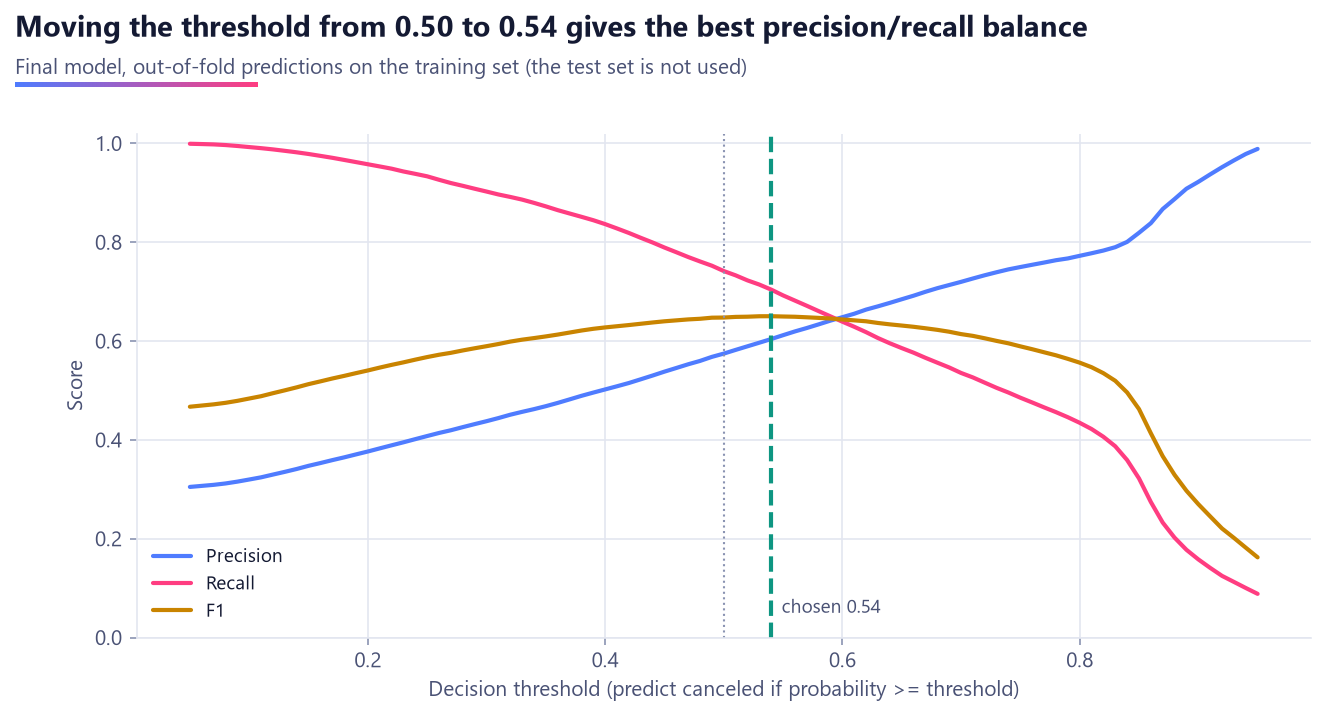

In [17]:
display(Image(FIG / "09_threshold_tuning.png", width=760))

## 10. Final evaluation on the untouched test set

The saved final model (`models/final_model.joblib`) is loaded and scored live on the test set.

In [18]:
model = joblib.load(config.FINAL_MODEL_PATH)
proba = model.predict_proba(dataset.x_test)[:, 1]
threshold = summary["final"]["threshold"]
pd.DataFrame(
    {
        "threshold 0.50": compute_metrics(dataset.y_test, proba),
        f"tuned {threshold:.2f}": compute_metrics(dataset.y_test, proba, threshold),
    }
).rename(index=config.METRIC_LABELS)

,threshold 0.50,tuned 0.54
Accuracy,0.7836,0.7960
Precision,0.5836,0.6120
Recall,0.7445,0.7062
F1,0.6543,0.6557
ROC-AUC,0.8553,0.8553
PR-AUC,0.7210,0.7210


In [19]:
pd.DataFrame(report_dict(dataset.y_test, proba, threshold)).T

,precision,recall,f1-score,support
Not canceled,0.8816,0.8300,0.8550,12643.000
Canceled,0.6120,0.7062,0.6557,4799.000
accuracy,0.7960,0.7960,0.7960,0.796
macro avg,0.7468,0.7681,0.7554,17442.000
weighted avg,0.8074,0.7960,0.8002,17442.000


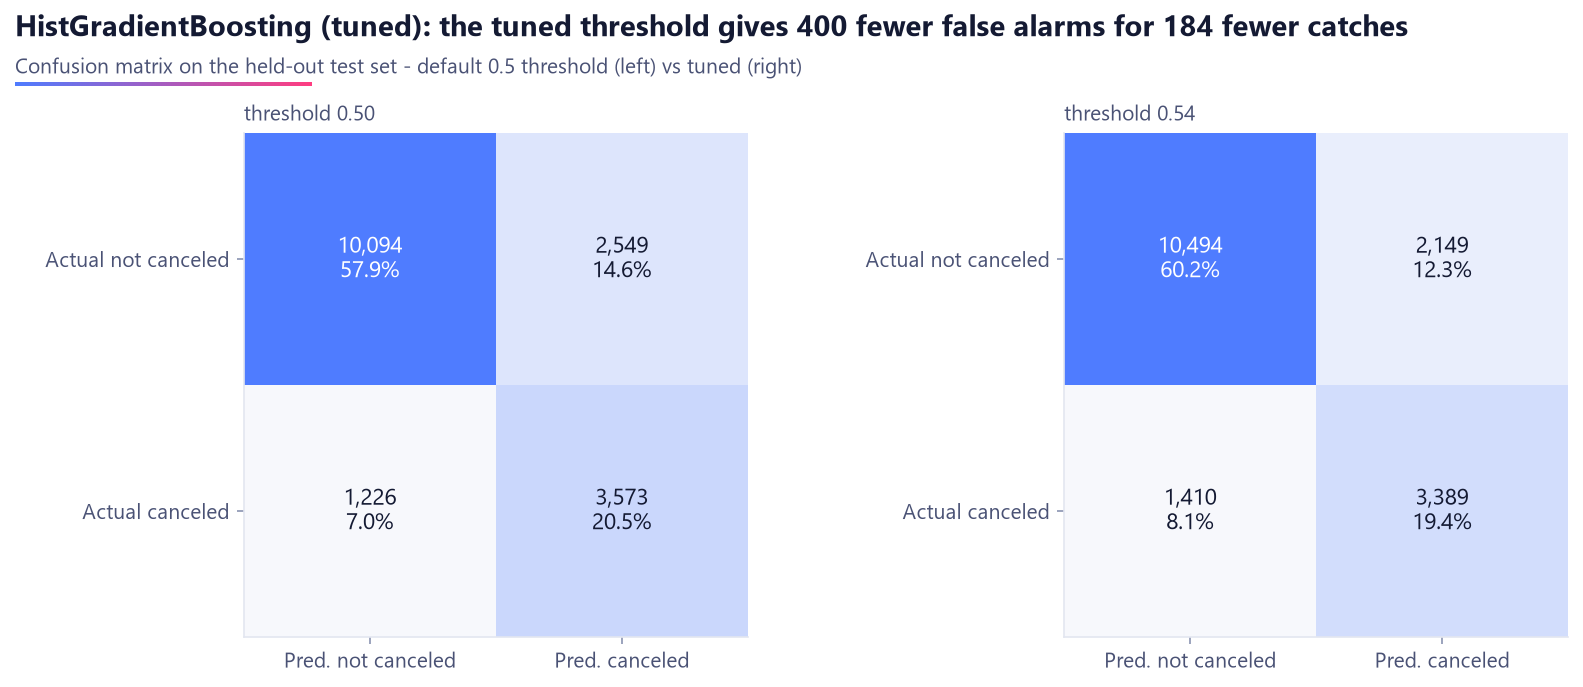

In [20]:
display(Image(FIG / "05_confusion_matrix.png", width=860))

## 11. Explainability

Permutation importance of the final model on the test set (raw input columns, so a categorical
column counts as one feature), plus the impurity importances of the tree models.

In [21]:
pd.DataFrame(summary["permutation"]).head(12)

,feature,importance_mean,importance_std
0,total_of_special_requests,0.1210,0.0042
1,lead_time,0.1118,0.0039
2,previous_cancel_ratio,0.0723,0.0042
3,market_segment,0.0702,0.0042
4,agent,0.0648,0.0037
5,deposit_type,0.0615,0.0017
6,required_car_parking_spaces,0.0611,0.0017
7,customer_type,0.0537,0.0024
8,previous_bookings_not_canceled,0.0111,0.0009
9,arrival_month_num,0.0080,0.0006


In [22]:
for item in summary["insights"]:
    print("-", item["text"])

- Bookings with 1+ total_of_special_requests cancel 22%, vs 33% with none.
- Top quarter of lead_time (>= 125) cancels 38%, bottom quarter (<= 11) 10%.
- Bookings with previous_cancel_ratio > 0 cancel 67%, vs 27% otherwise.
- market_segment = Online TA cancels 35% of the time, vs 12% for Corporate.
- agent = 9 cancels 40% of the time, vs 6% for 28.
- deposit_type = Non Refund cancels 95% of the time, vs 27% for No Deposit.
- Bookings with 1+ required_car_parking_spaces cancel 0%, vs 30% with none.
- customer_type = Transient cancels 30% of the time, vs 15% for Transient-Party.


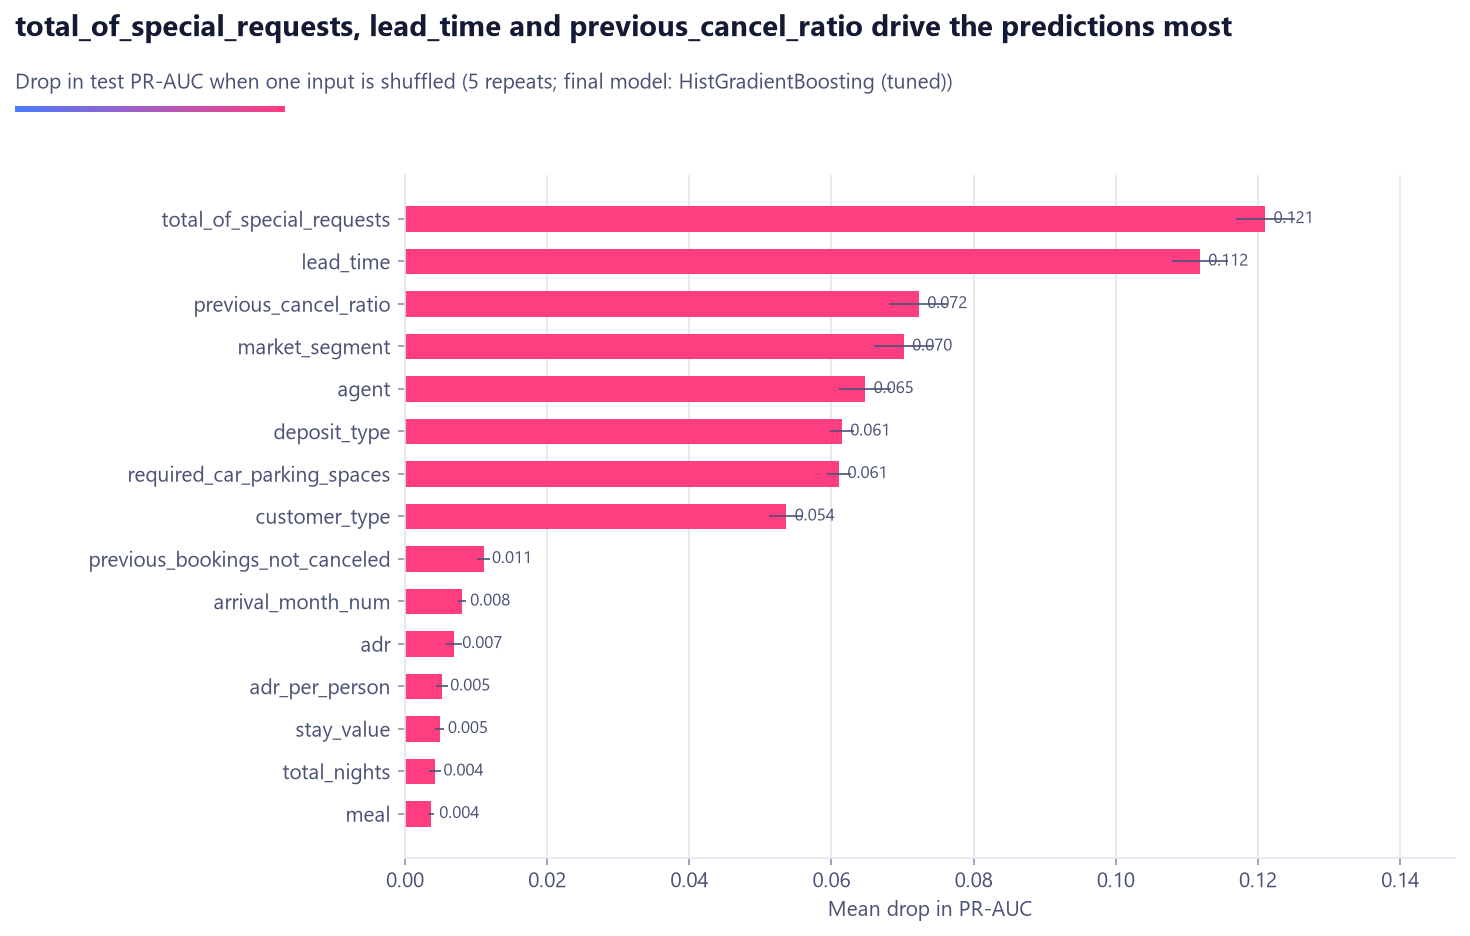

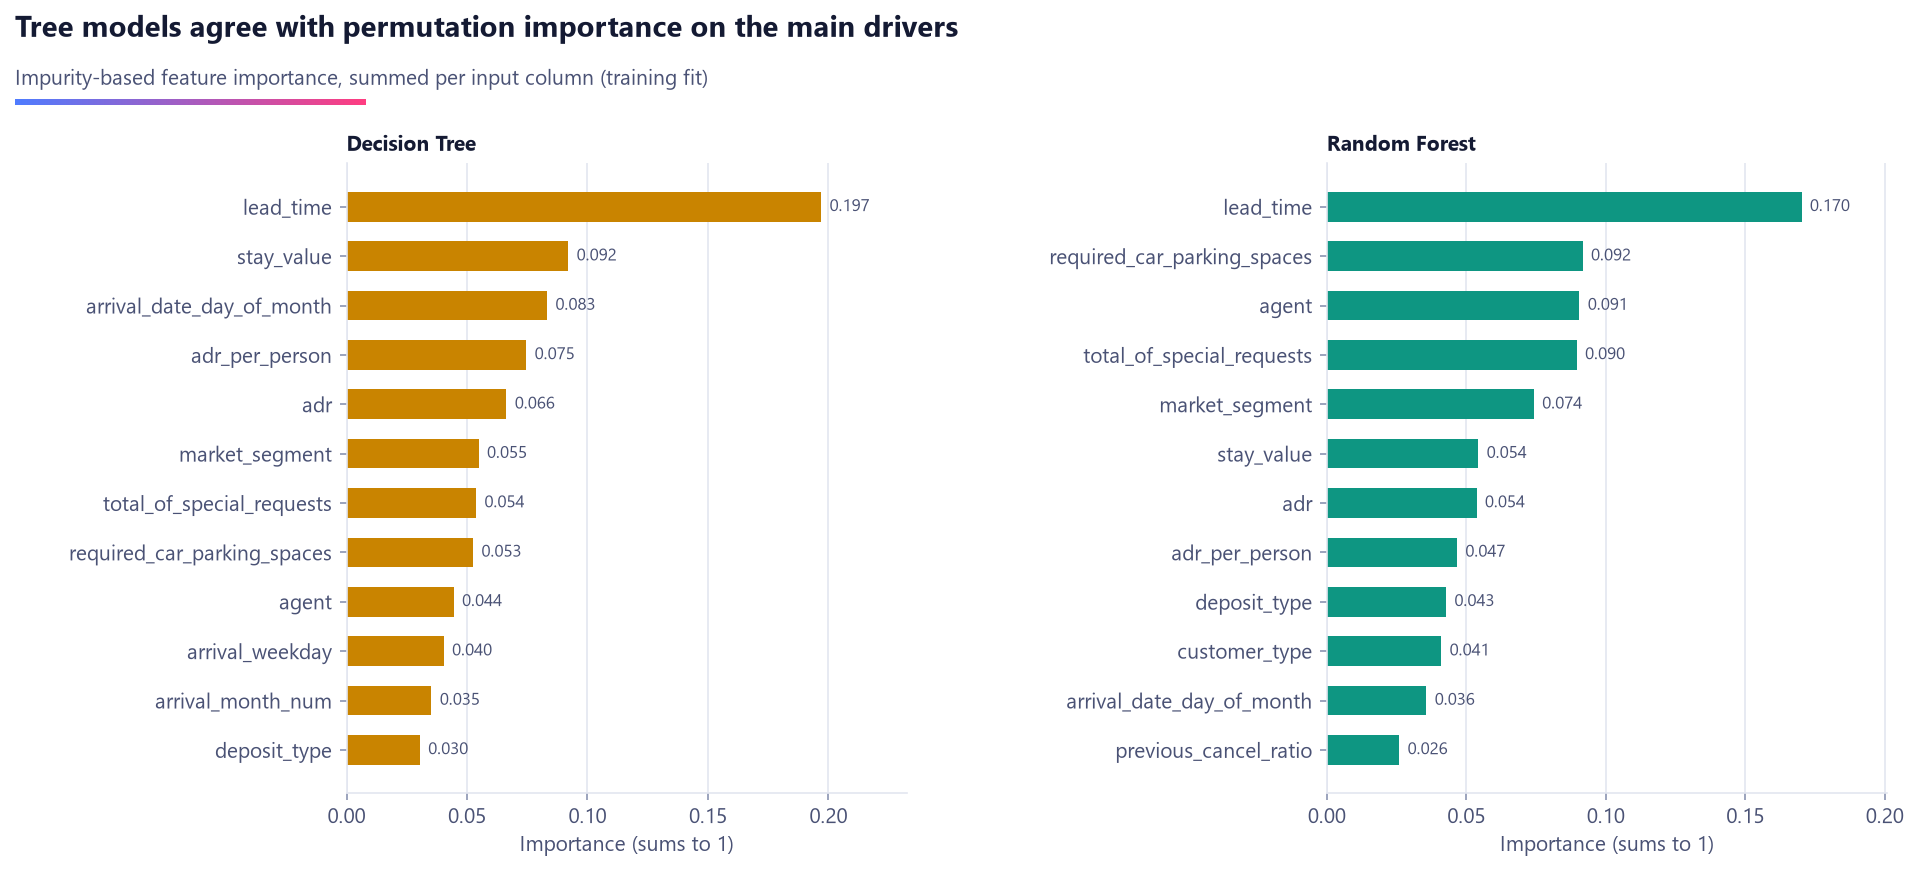

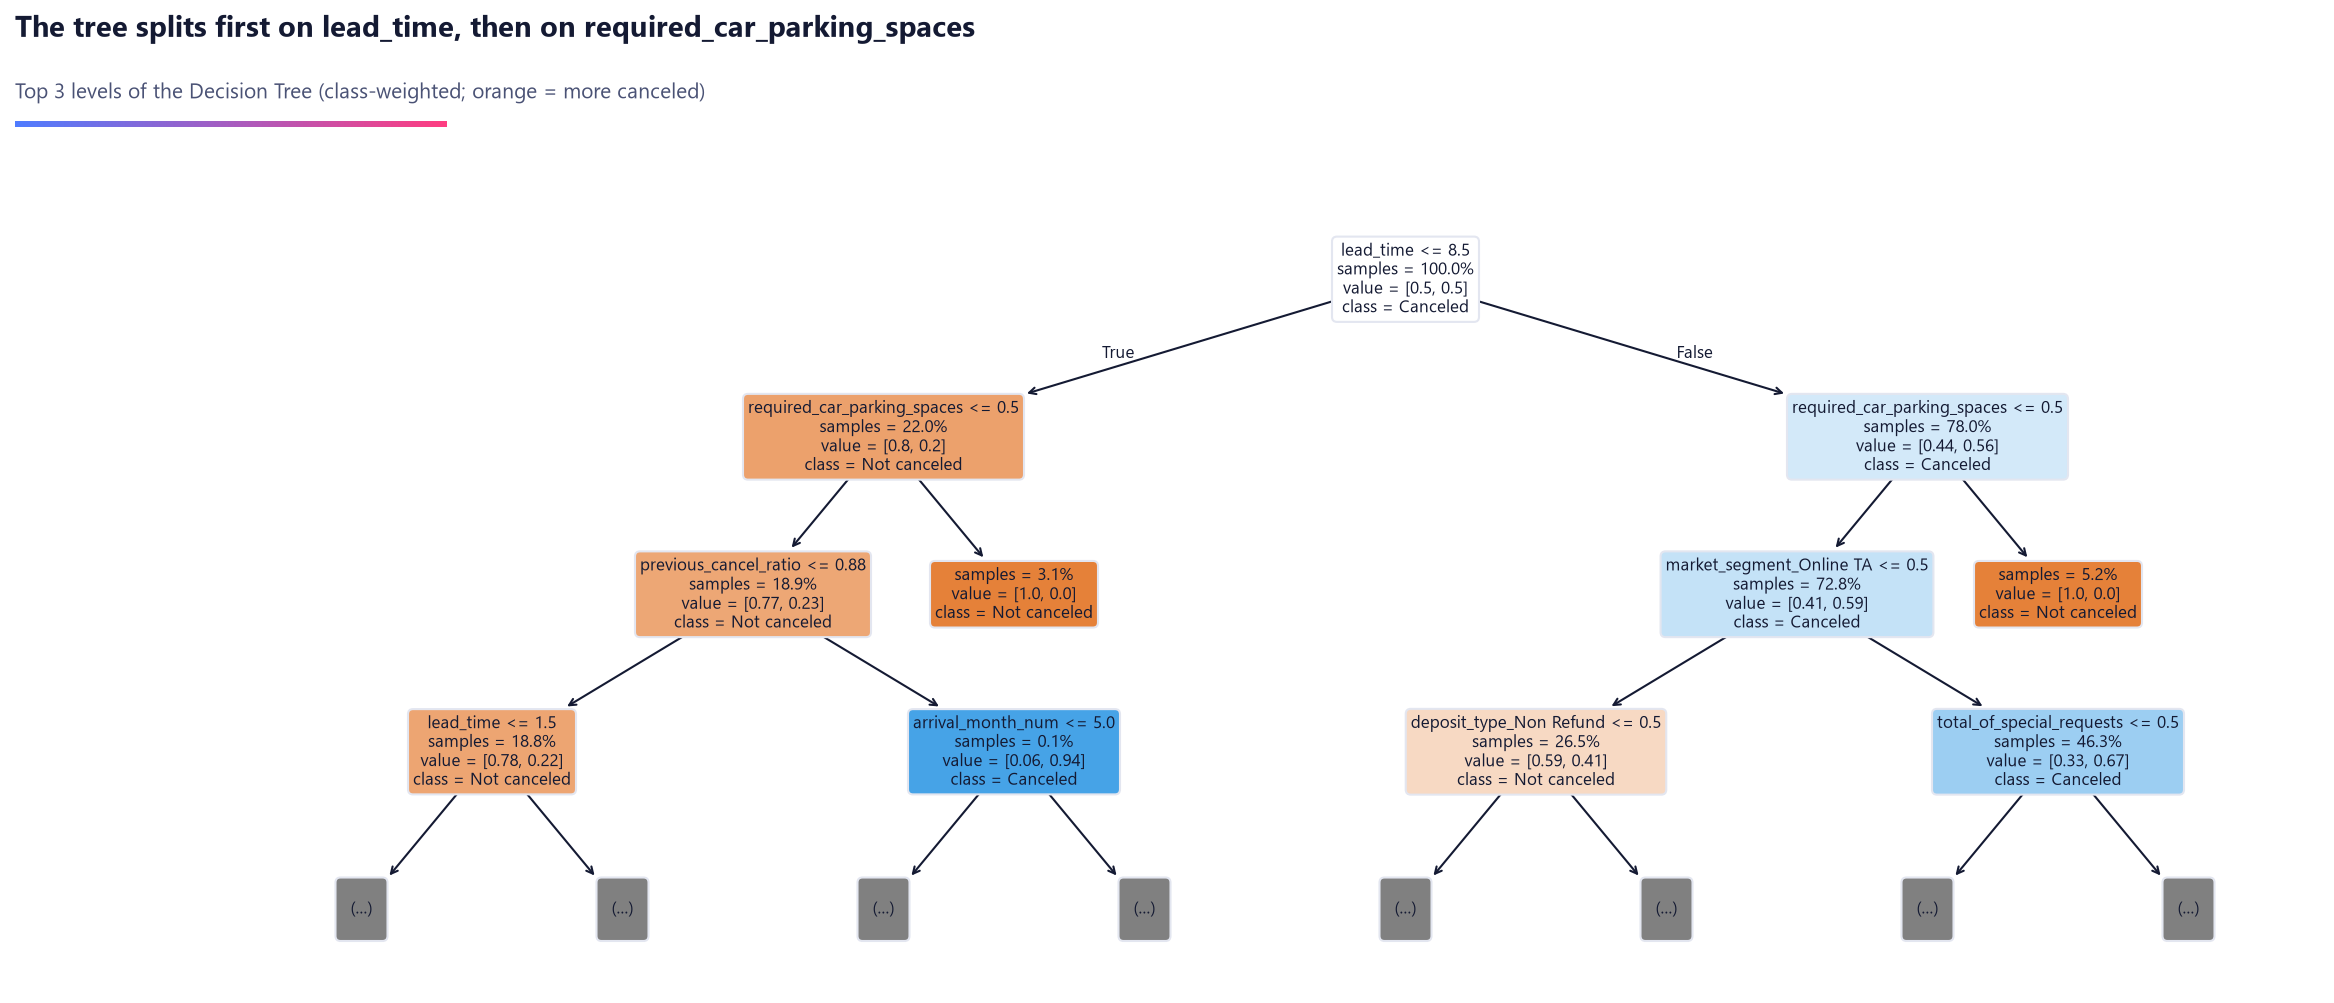

In [23]:
display(Image(FIG / "10_permutation_importance.png", width=820))
display(Image(FIG / "11_tree_feature_importance.png", width=900))
display(Image(FIG / "12_decision_tree_top_levels.png", width=980))

## 12. Temporal validation: does performance hold over time?

In [24]:
t = summary["temporal"]
print(
    f"Train arrivals {t['train_period'][0]} -> {t['train_period'][1]} ({t['train_rows']:,} rows, {t['train_cancel_rate']:.1%} canceled)"
)
print(
    f"Test  arrivals {t['test_period'][0]} -> {t['test_period'][1]} ({t['test_rows']:,} rows, {t['test_cancel_rate']:.1%} canceled)"
)
pd.DataFrame(
    [
        {
            "model": m["name"],
            f"random split {label}": m["test"][metric],
            f"temporal {label}": t["metrics"][m["key"]][metric],
            "change": t["metrics"][m["key"]][metric] - m["test"][metric],
        }
        for m in summary["models"]
        if m["key"] != "dummy"
    ]
)

Train arrivals 2015-07-01 -> 2017-05-01 (69,664 rows, 25.7% canceled)
Test  arrivals 2017-05-02 -> 2017-08-31 (17,544 rows, 34.7% canceled)


,model,random split PR-AUC,temporal PR-AUC,change
0,Logistic Regression,0.6715,0.6773,0.0058
1,Decision Tree,0.4294,0.4286,-0.0008
2,Random Forest,0.7040,0.6399,-0.0641
3,Random Forest (tuned),0.7232,0.6527,-0.0705
4,HistGradientBoosting,0.7220,0.6661,-0.0559
5,HistGradientBoosting (tuned),0.7210,0.6704,-0.0506
6,K-Nearest Neighbors,0.6214,0.5718,-0.0496


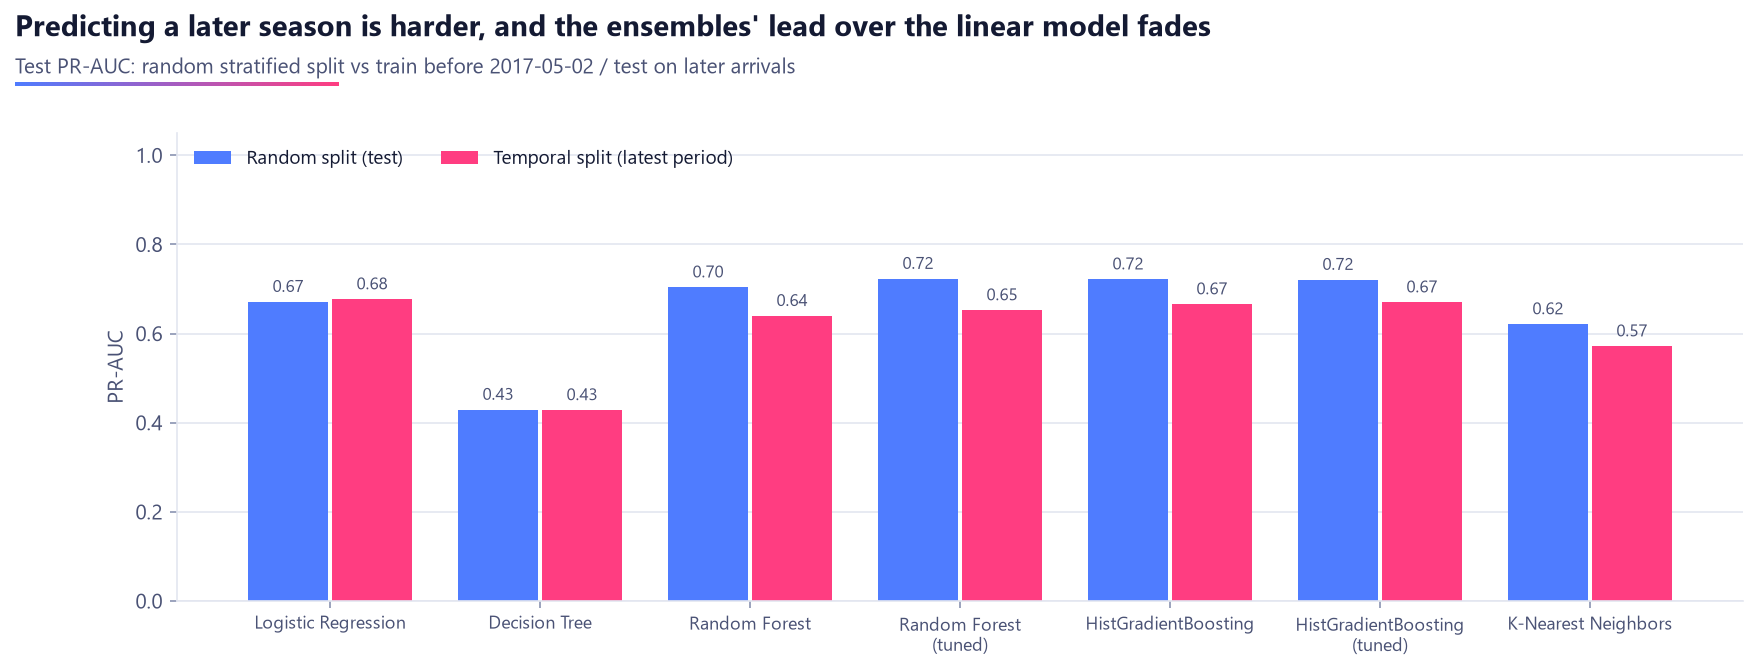

In [25]:
display(Image(FIG / "13_temporal_vs_random.png", width=900))

## 13. Conclusions

* **Model**: the selected model is tied for the best cross-validated PR-AUC, has the smallest
  train-CV gap of the tied models, and its file is small and fast enough for a free 512 MB host
  (section 8).
* **Leakage precaution**: nationality (`country`, `is_domestic`) is excluded because it may only
  be recorded at check-in. It would add about 0.06 PR-AUC (section 2, "With vs without country"),
  the price of a model that only uses booking-time information.
* **Generalisation**: CV and test scores agree closely, so the validation setup works. The
  unconstrained Decision Tree and KNN clearly overfit; Logistic Regression has no gap but sits
  on the underfitting border, about 0.04 below the ensembles.
* **Business use**: the tuned threshold gives fewer false alarms than 0.5 for a few more missed
  cancellations. The web app's cost calculator lets a hotel pick a threshold from its own costs.
* **Caveat**: on a future period every model drops and Logistic Regression catches up with the
  ensembles (section 12), so in production the model should be retrained regularly, the
  threshold re-checked each season, and the simpler model kept as a monitored fallback.

All decisions are logged in `docs/decisions.md`.